In [1]:
# Support Vector Machine

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [5]:
import pandas as  pd
data = load_breast_cancer()

X=pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

print(X.shape)
print(X.head())

(569, 30)
   mean radius  mean texture  ...  worst symmetry  worst fractal dimension
0        17.99         10.38  ...          0.4601                  0.11890
1        20.57         17.77  ...          0.2750                  0.08902
2        19.69         21.25  ...          0.3613                  0.08758
3        11.42         20.38  ...          0.6638                  0.17300
4        20.29         14.34  ...          0.2364                  0.07678

[5 rows x 30 columns]


In [7]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,
     stratify=y)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [12]:
model = SVC(
kernel ="rbf",
C=1.0,
gamma="scale"
)

In [13]:
model.fit(
    X_train_scaled,y_train
)

print("SVM model trained successfully")

SVM model trained successfully


In [14]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:10])

[0 1 0 1 0 1 1 0 0 0]


In [15]:
accuracy = accuracy_score(y_test,y_pred)

print("Accuracy:", accuracy *100,"%")

Accuracy: 98.24561403508771 %


In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [17]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[41  1]
 [ 1 71]]


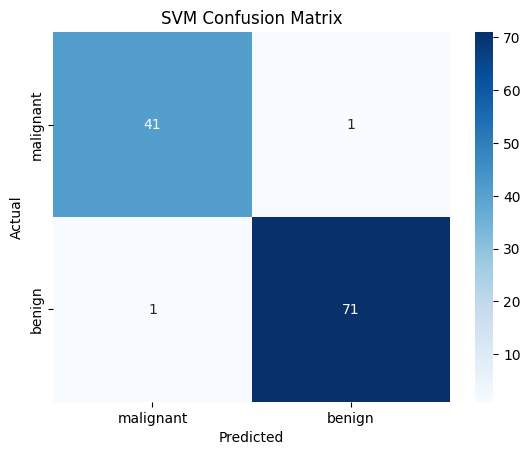

In [18]:
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()